# The Setup

The following imports are used to support data loading, inspection and plotting. The predcition task at hand is a binary classification problem.
It identifies whether a candidate is a pulsar (1) or not a pulsar (0)

In [67]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score,  accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone
import sklearn
from sklearn.dummy import DummyClassifier

# Load data and the inital audit
The dataset is loaded along with its nine column names.
Inspect the structure, variable types, missing values, duplicate rows and the target value counts.

In [ ]:

columns=['profile_mean','profile_stdev','profile_skewness','profile_kurtosis','DM_mean','dm_stdev','dm_skewness','dm_kurtosis','class']
data = pd.read_csv(
    r"C:\Users\conor\Downloads\htru2 (1)\HTRU_2.csv",
    header=None,  
    names=columns
)
display(data.head())
print('Shape:', data.shape)
print('Columns:', data.columns.tolist())
print('Data types:\n', data.dtypes)
print("Duplicate rows:", data.duplicated().sum())
print("Missing values per column:\n", data.isna().sum())
display(data['class'].value_counts())


,profile_mean,profile_stdev,profile_skewness,profile_kurtosis,DM_mean,dm_stdev,dm_skewness,dm_kurtosis,class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


Shape: (17898, 9)
Columns: ['profile_mean', 'profile_stdev', 'profile_skewness', 'profile_kurtosis', 'DM_mean', 'dm_stdev', 'dm_skewness', 'dm_kurtosis', 'class']
Data types:
 profile_mean        float64
profile_stdev       float64
profile_skewness    float64
profile_kurtosis    float64
DM_mean             float64
dm_stdev            float64
dm_skewness         float64
dm_kurtosis         float64
class                 int64
dtype: object
0
profile_mean        0
profile_stdev       0
profile_skewness    0
profile_kurtosis    0
DM_mean             0
dm_stdev            0
dm_skewness         0
dm_kurtosis         0
class               0
dtype: int64


class
0    16259
1     1639
Name: count, dtype: int64

# Findings from inital audit

- The dataset contains 17,898 unique observations, comprised of eight input features and one target.
- All eight features are **float64** numerical measurements. The target is stored as an **int64**, its values represent two categories.
- There are no missing values or duplicate rows


# Feature summary
Summary of the eight input features, exlcluding the targert.
The table reports the count,mean,standard deviation,quartile ranges, min and max of the features.

In [ ]:
display(data.iloc[:, :8].describe())

       profile_mean  profile_stdev  profile_skewness  profile_kurtosis  \
count  17898.000000   17898.000000      17898.000000      17898.000000   
mean     111.079968      46.549532          0.477857          1.770279   
std       25.652935       6.843189          1.064040          6.167913   
min        5.812500      24.772042         -1.876011         -1.791886   
25%      100.929688      42.376018          0.027098         -0.188572   
50%      115.078125      46.947479          0.223240          0.198710   
75%      127.085938      51.023202          0.473325          0.927783   
max      192.617188      98.778911          8.069522         68.101622   

            DM_mean      dm_stdev   dm_skewness   dm_kurtosis  
count  17898.000000  17898.000000  17898.000000  17898.000000  
mean      12.614400     26.326515      8.303556    104.857709  
std       29.472897     19.470572      4.506092    106.514540  
min        0.213211      7.370432     -3.139270     -1.976976  
25%        1.

# Interpretation of the summary statistics of features
Several of the features have extreme values compared to the central range. 
DM_Mean has a median of 2.8, upper quartile of 5.46 and a maximum of 223.39. Its mean (12.61) is much higher than its median, which indicates a long upper tail.
Similarily, dm_kurtosis has an upper quartile range of 139.31 but a maximum of 1,119.

The feature ranges and spreads also differ considerably. 
This helps inform any decisions made on scaling.


# Target Distribution

Compare the number of non pulsar and pulsar observations to view the class imbalance.

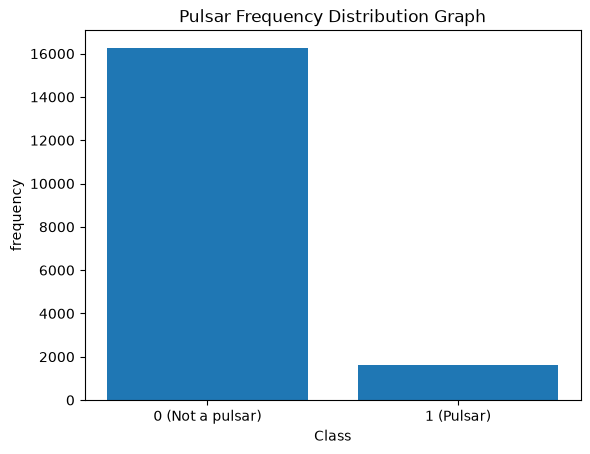

In [70]:
counts = data['class'].value_counts()
plt.bar(counts.index, counts.values)
plt.xlabel('Class')
plt.ylabel('frequency')
plt.xticks([0,1],['0 (Not a pulsar)' , '1 (Pulsar)'])
plt.title('Pulsar Frequency Distribution Graph')
plt.show()

# Class imbalance implications

- **Non Pulsars (0)**: 16,259 observations (90.84%)
- **Pulsars (1)**: 1,639 observations (9.16%)

The dataset is largely imbalanced, always predicting a non pulsar would achieve approximately 90.84% accuracy on the entire datset, while also detecting no pulsars.
Accuracy alone is therefore misleading. Evaluation of the data should also consider precision, recall and F1, with a confusion matrix to help aid and explain the errors.


# Potential Outliers

Inspect each numerical fetature using box plots. Each subplot will have its own scale as feature range differ.
The boxer covers Q1 to Q3, the line marks the median, and points beyond the whiskers flag any potential outliers using the 1.5 * IQR rule.

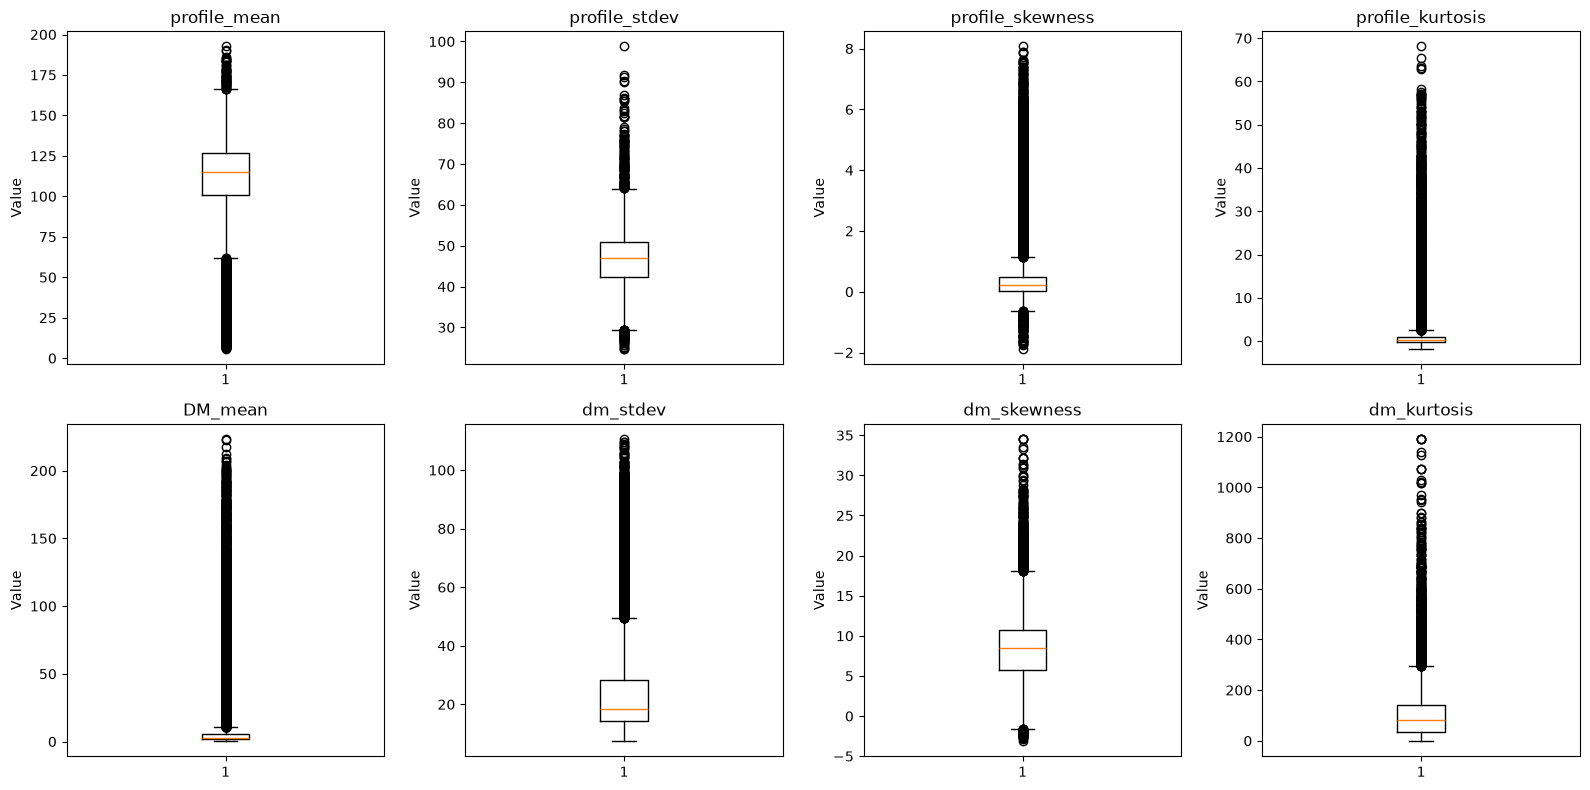

In [71]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()  # Make the grid easy to loop through

for i, column in enumerate(data.columns[:8]):  # Exclude class
    axes[i].boxplot(data[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Value')

plt.tight_layout()  # Prevent overlapping titles and labels
plt.show()

# Outlier interpretation and initial decision
The summary statistics show that all eight features contain at least one value outside their 1.5*IQR boundaries.
The box plot helps show wheres outliers occur, although overlapping points mean they do not provide reliable counts.
A statistical flag does not establish that an observation is incorrect. Extreme values could be valid measurements and could help distinguish the two classes. For the initial baseline, I will retain these observations, because this audit has not established that they are errors. Any later decision to transform or remove values should be justified using training data, without using the final test set to choose the procedure.


In [72]:
x = data.iloc[:,:8]
y = data['class']

x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42,test_size=.2,stratify=y)


pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])


dclf = DummyClassifier(strategy = 'most_frequent')
dclf.fit(x_train,y_train)

baseline_pred = dclf.predict(x_test)

print("Accuracy:", accuracy_score(y_test, baseline_pred))
print("Precision:", precision_score(y_test, baseline_pred, zero_division=0))
print("Recall:", recall_score(y_test, baseline_pred, zero_division=0))
print("F1:", f1_score(y_test, baseline_pred, zero_division=0))

Accuracy: 0.9083798882681564
Precision: 0.0
Recall: 0.0
F1: 0.0
